# 04 — Shared Baseline Modelling and OOF Evaluation

## Purpose

This notebook establishes simple reference performance levels before the six
advanced headline models are trained.

The mandatory baselines are:

1. `DummyClassifier(strategy="prior")`
2. `DummyClassifier(strategy="most_frequent")`

These models are intentionally simple. Their purpose is not to solve the
resignation-prediction problem, but to provide transparent no-skill references
that later models must outperform.

All baseline evaluation uses:

- the frozen 80,000-row development partition;
- the exact five saved outer CV folds;
- one out-of-fold prediction per development record;
- the same target orientation used by the full project (`Resigned=True` is positive).

### Important boundaries

This notebook does **not**:

- create a new train/test split;
- create new CV folds;
- use the formal 20% holdout for model evaluation or decisions;
- train any of the six headline models;
- perform final model selection;
- perform calibration selection;
- select an operational classification threshold;
- perform final fairness evaluation;
- perform retention prioritization;
- apply SMOTE or other resampling;
- create a universal preprocessed dataset.

The optional Logistic Regression section is a conventional reference only and
is disabled by default. It is not one of the six required headline models.

In [1]:
# ------------------------------------------------------------
# IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

from pathlib import Path
import hashlib
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyYAML is used to read the frozen feature contract.
try:
    import yaml
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "PyYAML is required for this notebook. "
        "Install it in the active environment with: pip install pyyaml"
    ) from exc


# scikit-learn tools used by the mandatory baselines.
try:
    from sklearn.dummy import DummyClassifier

    from sklearn.metrics import (
        accuracy_score,
        average_precision_score,
        balanced_accuracy_score,
        brier_score_loss,
        confusion_matrix,
        f1_score,
        precision_recall_curve,
        precision_score,
        recall_score,
        roc_auc_score,
    )

    # These imports are used only if the optional Logistic Regression
    # reference is explicitly enabled later in the notebook.
    from sklearn.compose import ColumnTransformer
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler

except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "scikit-learn is required for the baseline notebook. "
        "Install it in the active environment with: pip install scikit-learn"
    ) from exc


# Keep wide result tables readable in the notebook.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

print("Imports loaded successfully.")

Imports loaded successfully.


In [2]:
# ------------------------------------------------------------
# DEFINE PROJECT PATHS AND FILE-HASH HELPER
# ------------------------------------------------------------

# The notebook is inside notebooks/, so ".." is the project root.
project_root = Path("..").resolve()

# Frozen project inputs.
raw_data_file = (
    project_root
    / "data"
    / "raw"
    / "Extended_Employee_Performance_and_Productivity_Data.csv"
)

split_registry_file = (
    project_root
    / "data"
    / "processed"
    / "split_registry.csv"
)

feature_contract_file = (
    project_root
    / "configs"
    / "feature_contract.yaml"
)

# Baseline outputs.
baseline_results_folder = (
    project_root
    / "results"
    / "baselines"
)

baseline_results_folder.mkdir(
    parents=True,
    exist_ok=True,
)


def sha256_file(file_path: Path) -> str:
    """Return the SHA-256 checksum of a file."""
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


print("Project root:", project_root)
print("Raw dataset:", raw_data_file)
print("Split registry:", split_registry_file)
print("Feature contract:", feature_contract_file)
print("Baseline results folder:", baseline_results_folder)

Project root: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project
Raw dataset: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\data\raw\Extended_Employee_Performance_and_Productivity_Data.csv
Split registry: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\data\processed\split_registry.csv
Feature contract: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\configs\feature_contract.yaml
Baseline results folder: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\results\baselines


In [3]:
# ------------------------------------------------------------
# LOAD AND VERIFY THE FROZEN FEATURE CONTRACT
# ------------------------------------------------------------

if not feature_contract_file.exists():
    raise FileNotFoundError(
        f"Feature contract not found:\n{feature_contract_file}"
    )


with open(feature_contract_file, "r", encoding="utf-8") as file:
    feature_contract = yaml.safe_load(file)


# The contract must already be frozen before baseline work begins.
contract_status = feature_contract["contract"]["status"]

if contract_status != "frozen":
    raise ValueError(
        "Feature contract is not marked as frozen."
    )


# Read the authoritative target and feature roles.
target_column = feature_contract["target"]["column"]
positive_class = feature_contract["target"]["positive_class"]
negative_class = feature_contract["target"]["negative_class"]

categorical_features = [
    item["name"]
    for item in feature_contract["categorical_features"]
]

numerical_features = [
    item["name"]
    for item in feature_contract["numerical_features"]
]

primary_model_features = feature_contract["primary_model_features"]

excluded_features = [
    item["column"]
    for item in feature_contract["excluded_features"]
]


# Verify the frozen shared feature structure.
if target_column != "Resigned":
    raise ValueError(
        f"Unexpected target column: {target_column}"
    )

if positive_class is not True:
    raise ValueError(
        "The positive class must be True."
    )

if negative_class is not False:
    raise ValueError(
        "The negative class must be False."
    )

if len(categorical_features) != 4:
    raise ValueError(
        f"Expected 4 categorical predictors, found {len(categorical_features)}."
    )

if len(numerical_features) != 13:
    raise ValueError(
        f"Expected 13 numerical/ordinal predictors, found {len(numerical_features)}."
    )

if len(primary_model_features) != 17:
    raise ValueError(
        f"Expected 17 primary predictors, found {len(primary_model_features)}."
    )

if categorical_features + numerical_features != primary_model_features:
    raise ValueError(
        "Categorical + numerical feature lists do not exactly match "
        "the frozen primary feature list."
    )

if set(excluded_features).intersection(primary_model_features):
    raise ValueError(
        "At least one excluded field appears in primary_model_features."
    )


print("FEATURE CONTRACT VERIFICATION")
print("-" * 50)

print("Contract status:", contract_status)
print("Target:", target_column)
print("Positive class:", positive_class)
print("Negative class:", negative_class)
print("Primary predictors:", len(primary_model_features))
print("Categorical predictors:", len(categorical_features))
print("Numerical / ordinal predictors:", len(numerical_features))
print("Excluded fields:", excluded_features)

print("\nFrozen feature contract verification: PASSED")

FEATURE CONTRACT VERIFICATION
--------------------------------------------------
Contract status: frozen
Target: Resigned
Positive class: True
Negative class: False
Primary predictors: 17
Categorical predictors: 4
Numerical / ordinal predictors: 13
Excluded fields: ['Employee_ID', 'Hire_Date', 'Resigned']

Frozen feature contract verification: PASSED


In [4]:
# ------------------------------------------------------------
# VERIFY AND LOAD THE RAW DATASET AND SPLIT REGISTRY
# ------------------------------------------------------------

if not raw_data_file.exists():
    raise FileNotFoundError(
        f"Raw dataset not found:\n{raw_data_file}"
    )

if not split_registry_file.exists():
    raise FileNotFoundError(
        f"Split registry not found:\n{split_registry_file}"
    )


# Read expected fingerprints from the frozen contract.
expected_raw_sha256 = feature_contract["dataset"]["sha256"]
expected_registry_sha256 = feature_contract["split_registry"]["sha256"]

# Calculate actual fingerprints.
actual_raw_sha256 = sha256_file(raw_data_file)
actual_registry_sha256 = sha256_file(split_registry_file)


if actual_raw_sha256 != expected_raw_sha256:
    raise ValueError(
        "Raw dataset SHA-256 does not match the frozen contract."
    )

if actual_registry_sha256 != expected_registry_sha256:
    raise ValueError(
        "Split registry SHA-256 does not match the frozen contract."
    )


# Load verified files.
raw_df = pd.read_csv(raw_data_file)

split_registry = pd.read_csv(
    split_registry_file,
    dtype={"cv_fold": "Int64"},
)


# Verify raw dataset shape.
expected_rows = feature_contract["dataset"]["expected_rows"]
expected_columns = feature_contract["dataset"]["expected_columns"]

if raw_df.shape != (expected_rows, expected_columns):
    raise ValueError(
        f"Unexpected raw dataset shape: {raw_df.shape}. "
        f"Expected ({expected_rows}, {expected_columns})."
    )


# Verify the exact split-registry schema.
expected_registry_columns = [
    "Employee_ID",
    "partition",
    "cv_fold",
]

if split_registry.columns.tolist() != expected_registry_columns:
    raise ValueError(
        "Split registry columns do not match the frozen registry schema."
    )


print("INPUT FILE VERIFICATION")
print("-" * 50)

print("Raw dataset SHA-256:", actual_raw_sha256)
print("Split registry SHA-256:", actual_registry_sha256)
print("Raw dataset shape:", raw_df.shape)
print("Split registry shape:", split_registry.shape)

print("\nDataset and split registry verification: PASSED")

INPUT FILE VERIFICATION
--------------------------------------------------
Raw dataset SHA-256: 2b1e07caf58e7678a780d428c1a8893a95d9c4a556134fd8e7368db5ed596cdb
Split registry SHA-256: 87edc10ac38f2435c49beddbf412f9de293e3e0622558b27ffbdf31fadd7ea41
Raw dataset shape: (100000, 20)
Split registry shape: (100000, 3)

Dataset and split registry verification: PASSED


In [5]:
# ------------------------------------------------------------
# CREATE THE DEVELOPMENT-ONLY BASELINE DATASET
# ------------------------------------------------------------

# Employee_ID must be complete and unique in both files.
for data_name, dataframe in [
    ("raw dataset", raw_df),
    ("split registry", split_registry),
]:
    if dataframe["Employee_ID"].isna().any():
        raise ValueError(
            f"{data_name} contains missing Employee_ID values."
        )

    if dataframe["Employee_ID"].duplicated().any():
        raise ValueError(
            f"{data_name} contains duplicate Employee_ID values."
        )


# Both sources must refer to exactly the same employees.
if set(raw_df["Employee_ID"]) != set(split_registry["Employee_ID"]):
    raise ValueError(
        "Employee_ID membership differs between the raw data and split registry."
    )


# Merge by the stable record identifier.
merged_df = raw_df.merge(
    split_registry,
    on="Employee_ID",
    how="inner",
    validate="one_to_one",
)


if len(merged_df) != len(raw_df):
    raise ValueError(
        "Merged dataset does not contain all raw records."
    )


# Use only the official development partition for baseline CV.
development_df = (
    merged_df.loc[
        merged_df["partition"] == "development"
    ]
    .copy()
    .reset_index(drop=True)
)


expected_development_rows = feature_contract[
    "split_registry"
]["development_rows"]

expected_holdout_rows = feature_contract[
    "split_registry"
]["formal_holdout_rows"]

expected_cv_folds = feature_contract[
    "split_registry"
]["cv_folds"]


if len(development_df) != expected_development_rows:
    raise ValueError(
        f"Expected {expected_development_rows:,} development rows, "
        f"found {len(development_df):,}."
    )

if int((merged_df["partition"] == "holdout").sum()) != expected_holdout_rows:
    raise ValueError(
        "Formal holdout row count does not match the frozen contract."
    )

if not development_df["partition"].eq("development").all():
    raise ValueError(
        "Formal holdout contamination detected."
    )


# Verify exact frozen fold assignments.
fold_counts = (
    development_df["cv_fold"]
    .value_counts()
    .sort_index()
)

expected_fold_values = set(
    range(1, expected_cv_folds + 1)
)

actual_fold_values = set(
    development_df["cv_fold"]
    .dropna()
    .astype(int)
    .unique()
)

if actual_fold_values != expected_fold_values:
    raise ValueError(
        f"Unexpected development fold values: {actual_fold_values}"
    )

if not (fold_counts == 16_000).all():
    raise ValueError(
        "Every frozen CV fold must contain exactly 16,000 records."
    )

if development_df["cv_fold"].isna().any():
    raise ValueError(
        "At least one development record is missing a CV fold."
    )


# Verify exact development target counts.
development_target_counts = (
    development_df[target_column]
    .value_counts()
    .sort_index()
)

if int(development_target_counts[False]) != 71_992:
    raise ValueError(
        "Unexpected development count for Resigned=False."
    )

if int(development_target_counts[True]) != 8_008:
    raise ValueError(
        "Unexpected development count for Resigned=True."
    )


development_positive_rate = (
    development_df[target_column]
    .astype(int)
    .mean()
)


# Save the formal holdout IDs only for later leakage assertions.
# No holdout feature or target analysis is performed.
holdout_ids = set(
    split_registry.loc[
        split_registry["partition"] == "holdout",
        "Employee_ID",
    ]
)


print("DEVELOPMENT DATA VERIFICATION")
print("-" * 50)

print(f"Development rows: {len(development_df):,}")
print(f"Formal holdout rows reserved: {expected_holdout_rows:,}")
print("Formal holdout rows evaluated in this notebook: 0")
print()
print("Frozen fold counts:")
print(fold_counts.to_string())
print()
print("Development target counts:")
print(development_target_counts.to_string())
print(
    f"\nDevelopment positive prevalence: "
    f"{development_positive_rate * 100:.2f}%"
)

print("\nDevelopment-only baseline dataset verification: PASSED")

DEVELOPMENT DATA VERIFICATION
--------------------------------------------------
Development rows: 80,000
Formal holdout rows reserved: 20,000
Formal holdout rows evaluated in this notebook: 0

Frozen fold counts:
cv_fold
1    16000
2    16000
3    16000
4    16000
5    16000

Development target counts:
Resigned
False    71992
True      8008

Development positive prevalence: 10.01%

Development-only baseline dataset verification: PASSED


## Baseline Evaluation Design

All mandatory baselines are evaluated with **out-of-fold (OOF) prediction** on
the five frozen development folds.

For each fold:

1. four folds are used as the training portion;
2. the remaining saved fold is used as validation;
3. the baseline is fitted only on the training portion;
4. probabilities and hard predictions are generated for the validation fold;
5. the validation predictions are saved with `Employee_ID` and `cv_fold`.

After all five rounds, every development employee must have exactly one OOF
prediction per model.

The formal holdout is not used.

### Mandatory baselines

`DummyClassifier(strategy="prior")`

- learns only the training-fold class prior;
- produces the same class-prior probability for every validation record;
- provides a no-skill probability/ranking reference.

`DummyClassifier(strategy="most_frequent")`

- predicts the training-fold majority class;
- demonstrates why raw accuracy is misleading for an imbalanced target.

The primary comparison metric is **Average Precision / PR-AUC**.

In [6]:
# ------------------------------------------------------------
# DEFINE COMMON METRIC FUNCTION
# ------------------------------------------------------------

def calculate_binary_metrics(
    y_true,
    y_probability,
    y_pred,
) -> dict:
    """
    Calculate the shared binary-classification metrics used by
    the baseline workflow.

    The positive class is Resigned=True / 1.
    """

    # Convert values to consistent integer arrays.
    y_true = np.asarray(y_true).astype(int)
    y_probability = np.asarray(y_probability).astype(float)
    y_pred = np.asarray(y_pred).astype(int)


    # Probability sanity checks.
    if np.isnan(y_probability).any():
        raise ValueError(
            "Predicted probabilities contain missing values."
        )

    if (
        (y_probability < 0).any()
        or (y_probability > 1).any()
    ):
        raise ValueError(
            "Predicted probabilities must lie between 0 and 1."
        )


    # Compute the 2 × 2 confusion matrix with a fixed class order.
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()


    return {
        "pr_auc": average_precision_score(
            y_true,
            y_probability,
        ),
        "roc_auc": roc_auc_score(
            y_true,
            y_probability,
        ),
        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred,
        ),
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "brier_score": brier_score_loss(
            y_true,
            y_probability,
        ),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "predicted_positive_count": int(
            y_pred.sum()
        ),
        "predicted_positive_rate": float(
            y_pred.mean()
        ),
    }


print("Common metric function defined.")

Common metric function defined.


In [7]:
# ------------------------------------------------------------
# DEFINE REUSABLE DUMMY-BASELINE OOF FUNCTION
# ------------------------------------------------------------

def generate_dummy_oof_predictions(
    development_data: pd.DataFrame,
    strategy: str,
    model_name: str,
) -> pd.DataFrame:
    """
    Generate one OOF probability and one 0.5-threshold prediction
    for every development record using the frozen five folds.
    """

    prediction_parts = []


    for fold_number in range(1, 6):

        # Use the saved fold registry exactly as frozen.
        training_fold = development_data.loc[
            development_data["cv_fold"] != fold_number
        ]

        validation_fold = development_data.loc[
            development_data["cv_fold"] == fold_number
        ]


        # Frozen folds should contain 64,000 training rows
        # and 16,000 validation rows in every round.
        if len(training_fold) != 64_000:
            raise ValueError(
                f"Fold {fold_number}: expected 64,000 training rows, "
                f"found {len(training_fold):,}."
            )

        if len(validation_fold) != 16_000:
            raise ValueError(
                f"Fold {fold_number}: expected 16,000 validation rows, "
                f"found {len(validation_fold):,}."
            )


        # DummyClassifier ignores predictor information, but sklearn
        # still expects an X input. A single constant column makes it
        # explicit that these baselines are not using employee features.
        X_train_dummy = np.zeros(
            shape=(len(training_fold), 1),
            dtype=np.float32,
        )

        X_validation_dummy = np.zeros(
            shape=(len(validation_fold), 1),
            dtype=np.float32,
        )

        y_train = training_fold[target_column]
        y_validation = validation_fold[target_column]


        # Fit the requested no-skill strategy on training data only.
        baseline_model = DummyClassifier(
            strategy=strategy,
        )

        baseline_model.fit(
            X_train_dummy,
            y_train,
        )


        # Locate the probability column corresponding to Resigned=True.
        class_list = list(
            baseline_model.classes_
        )

        if True not in class_list:
            raise ValueError(
                f"Fold {fold_number}: positive class True is missing "
                "from the trained DummyClassifier."
            )

        positive_class_index = class_list.index(
            True
        )


        validation_probability = (
            baseline_model
            .predict_proba(
                X_validation_dummy
            )[:, positive_class_index]
        )


        # Use the common reference threshold of 0.5 for hard predictions.
        validation_prediction = (
            validation_probability >= 0.5
        ).astype(int)


        fold_predictions = pd.DataFrame(
            {
                "Employee_ID": (
                    validation_fold["Employee_ID"]
                    .to_numpy()
                ),
                "cv_fold": (
                    validation_fold["cv_fold"]
                    .astype(int)
                    .to_numpy()
                ),
                "y_true": (
                    y_validation
                    .astype(int)
                    .to_numpy()
                ),
                "model_name": model_name,
                "y_probability": validation_probability,
                "y_pred_0_5": validation_prediction,
            }
        )


        prediction_parts.append(
            fold_predictions
        )


    # Combine the five validation folds into one OOF table.
    oof_predictions = (
        pd.concat(
            prediction_parts,
            ignore_index=True,
        )
        .sort_values("Employee_ID")
        .reset_index(drop=True)
    )


    return oof_predictions


print("Dummy OOF generation function defined.")

Dummy OOF generation function defined.


In [8]:
# ------------------------------------------------------------
# DEFINE STRICT OOF VALIDATION FUNCTION
# ------------------------------------------------------------

development_id_set = set(
    development_df["Employee_ID"]
)


def validate_oof_predictions(
    oof_predictions: pd.DataFrame,
    model_name: str,
) -> None:
    """
    Validate coverage, row identity, probability range, fold identity,
    target orientation, and formal-holdout isolation.
    """

    expected_columns = [
        "Employee_ID",
        "cv_fold",
        "y_true",
        "model_name",
        "y_probability",
        "y_pred_0_5",
    ]


    if oof_predictions.columns.tolist() != expected_columns:
        raise ValueError(
            f"{model_name}: unexpected OOF prediction columns."
        )


    # Every development employee must appear exactly once.
    if len(oof_predictions) != 80_000:
        raise ValueError(
            f"{model_name}: expected 80,000 OOF rows, "
            f"found {len(oof_predictions):,}."
        )

    if oof_predictions["Employee_ID"].duplicated().any():
        raise ValueError(
            f"{model_name}: duplicate Employee_ID values found in OOF predictions."
        )

    if oof_predictions["Employee_ID"].isna().any():
        raise ValueError(
            f"{model_name}: missing Employee_ID values found in OOF predictions."
        )


    prediction_id_set = set(
        oof_predictions["Employee_ID"]
    )

    if prediction_id_set != development_id_set:
        raise ValueError(
            f"{model_name}: OOF Employee_ID set does not exactly "
            "match the development partition."
        )


    # No formal holdout employee may appear in OOF baseline predictions.
    holdout_overlap = (
        prediction_id_set
        .intersection(holdout_ids)
    )

    if holdout_overlap:
        raise ValueError(
            f"{model_name}: formal holdout Employee_ID contamination detected."
        )


    # Every saved frozen fold must appear.
    actual_folds = set(
        oof_predictions["cv_fold"]
        .astype(int)
        .unique()
    )

    if actual_folds != {1, 2, 3, 4, 5}:
        raise ValueError(
            f"{model_name}: OOF folds are not exactly 1 through 5."
        )


    # Each OOF fold must contain exactly 16,000 validation predictions.
    oof_fold_counts = (
        oof_predictions["cv_fold"]
        .value_counts()
        .sort_index()
    )

    if not (oof_fold_counts == 16_000).all():
        raise ValueError(
            f"{model_name}: OOF fold counts are not exactly 16,000 each."
        )


    # No predictions or targets may be missing.
    required_non_null_columns = [
        "y_true",
        "model_name",
        "y_probability",
        "y_pred_0_5",
    ]

    if oof_predictions[
        required_non_null_columns
    ].isna().any().any():
        raise ValueError(
            f"{model_name}: missing values detected in required OOF fields."
        )


    # Probability range must be valid.
    if not oof_predictions[
        "y_probability"
    ].between(0, 1).all():
        raise ValueError(
            f"{model_name}: probability outside [0, 1]."
        )


    # The saved y_true values must exactly match the source development target.
    source_target = (
        development_df[
            [
                "Employee_ID",
                target_column,
            ]
        ]
        .rename(
            columns={
                target_column: "source_y_true",
            }
        )
    )

    target_check = (
        oof_predictions[
            [
                "Employee_ID",
                "y_true",
            ]
        ]
        .merge(
            source_target,
            on="Employee_ID",
            how="left",
            validate="one_to_one",
        )
    )

    if not (
        target_check["y_true"].astype(int)
        == target_check["source_y_true"].astype(int)
    ).all():
        raise ValueError(
            f"{model_name}: saved y_true values do not match the source target."
        )


    print(
        f"{model_name}: OOF validation PASSED "
        f"({len(oof_predictions):,} rows)"
    )


print("OOF validation function defined.")

OOF validation function defined.


## Mandatory Baseline 1 — Dummy Prior

`DummyClassifier(strategy="prior")` learns only the class distribution in each
training fold.

For each outer CV round it assigns every validation employee the same positive
probability, approximately equal to the resignation prevalence in the
corresponding training data.

Because all records receive the same score, this baseline has no employee-level
ranking information. It provides a useful reference for PR-AUC, ROC-AUC, and
probability-quality metrics.

In [9]:
# ------------------------------------------------------------
# RUN MANDATORY DUMMY PRIOR BASELINE
# ------------------------------------------------------------

dummy_prior_model_name = "Dummy Prior"

dummy_prior_oof = generate_dummy_oof_predictions(
    development_data=development_df,
    strategy="prior",
    model_name=dummy_prior_model_name,
)


# Perform strict OOF validation before saving.
validate_oof_predictions(
    dummy_prior_oof,
    dummy_prior_model_name,
)


display(
    dummy_prior_oof.head(10)
)


# Save the verified OOF predictions.
dummy_prior_oof_file = (
    baseline_results_folder
    / "dummy_prior_oof_predictions.csv"
)

dummy_prior_oof.to_csv(
    dummy_prior_oof_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)


print(
    "\nDummy prior OOF predictions saved to:",
    dummy_prior_oof_file,
)

Dummy Prior: OOF validation PASSED (80,000 rows)


,Employee_ID,cv_fold,y_true,model_name,y_probability,y_pred_0_5
0,1,3,0,Dummy Prior,0.100094,0
1,2,3,0,Dummy Prior,0.100094,0
2,4,5,0,Dummy Prior,0.100094,0
3,5,3,0,Dummy Prior,0.100094,0
4,7,3,0,Dummy Prior,0.100094,0
5,8,5,0,Dummy Prior,0.100094,0
6,9,5,0,Dummy Prior,0.100094,0
7,10,5,0,Dummy Prior,0.100094,0
8,11,5,0,Dummy Prior,0.100094,0
9,12,4,0,Dummy Prior,0.100094,0



Dummy prior OOF predictions saved to: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\results\baselines\dummy_prior_oof_predictions.csv


## Mandatory Baseline 2 — Dummy Most Frequent

`DummyClassifier(strategy="most_frequent")` predicts the majority class learned
from each training fold.

Because approximately 90% of development records are `Resigned=False`, this
baseline is expected to classify every validation employee as the negative
class.

Its purpose is to demonstrate why high raw accuracy does not imply useful
positive-class detection.

In [10]:
# ------------------------------------------------------------
# RUN MANDATORY DUMMY MOST-FREQUENT BASELINE
# ------------------------------------------------------------

dummy_most_frequent_model_name = "Dummy Most Frequent"

dummy_most_frequent_oof = generate_dummy_oof_predictions(
    development_data=development_df,
    strategy="most_frequent",
    model_name=dummy_most_frequent_model_name,
)


# Perform strict OOF validation before saving.
validate_oof_predictions(
    dummy_most_frequent_oof,
    dummy_most_frequent_model_name,
)


display(
    dummy_most_frequent_oof.head(10)
)


# Save the verified OOF predictions.
dummy_most_frequent_oof_file = (
    baseline_results_folder
    / "dummy_most_frequent_oof_predictions.csv"
)

dummy_most_frequent_oof.to_csv(
    dummy_most_frequent_oof_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)


print(
    "\nDummy most-frequent OOF predictions saved to:",
    dummy_most_frequent_oof_file,
)

Dummy Most Frequent: OOF validation PASSED (80,000 rows)


,Employee_ID,cv_fold,y_true,model_name,y_probability,y_pred_0_5
0,1,3,0,Dummy Most Frequent,0.0,0
1,2,3,0,Dummy Most Frequent,0.0,0
2,4,5,0,Dummy Most Frequent,0.0,0
3,5,3,0,Dummy Most Frequent,0.0,0
4,7,3,0,Dummy Most Frequent,0.0,0
5,8,5,0,Dummy Most Frequent,0.0,0
6,9,5,0,Dummy Most Frequent,0.0,0
7,10,5,0,Dummy Most Frequent,0.0,0
8,11,5,0,Dummy Most Frequent,0.0,0
9,12,4,0,Dummy Most Frequent,0.0,0



Dummy most-frequent OOF predictions saved to: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\results\baselines\dummy_most_frequent_oof_predictions.csv


## Optional Conventional Reference — Logistic Regression

A simple Logistic Regression benchmark may be useful as a conventional
feature-based reference, but it is **not one of the six headline models**.

It is disabled by default so the mandatory baseline notebook remains lightweight
and cannot delay the advanced-model workstreams.

If the group explicitly decides to run it:

- the frozen 17-feature contract is used;
- categorical encoding is fitted inside each outer training fold;
- numerical standardization is fitted inside each outer training fold;
- no formal holdout data is used;
- no additional private CV folds are created;
- the configuration below is a fixed reference configuration, not a
  hyperparameter-search result.

Headline-model hyperparameter tuning is handled in the six individual model
workstreams.

In [11]:
# ------------------------------------------------------------
# OPTIONAL LOGISTIC REGRESSION SWITCH
# ------------------------------------------------------------

# Leave this False unless the group explicitly decides to include
# Logistic Regression as an additional conventional reference.
RUN_OPTIONAL_LOGISTIC_REGRESSION = False

print(
    "Optional Logistic Regression enabled:",
    RUN_OPTIONAL_LOGISTIC_REGRESSION,
)

Optional Logistic Regression enabled: False


In [12]:
# ------------------------------------------------------------
# OPTIONAL LOGISTIC REGRESSION OOF WORKFLOW
# ------------------------------------------------------------

logistic_model_name = "Logistic Regression (Optional)"
logistic_oof = None
logistic_oof_file = None


if RUN_OPTIONAL_LOGISTIC_REGRESSION:

    logistic_prediction_parts = []


    for fold_number in range(1, 6):

        training_fold = development_df.loc[
            development_df["cv_fold"] != fold_number
        ]

        validation_fold = development_df.loc[
            development_df["cv_fold"] == fold_number
        ]


        # Preprocessing is created fresh for every fold so no fitted
        # state can leak across outer validation folds.
        logistic_preprocessor = ColumnTransformer(
            transformers=[
                (
                    "categorical",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=True,
                    ),
                    categorical_features,
                ),
                (
                    "numerical",
                    StandardScaler(),
                    numerical_features,
                ),
            ],
            remainder="drop",
        )


        # Fixed transparent reference configuration.
        # This is intentionally not a headline-model tuning search.
        logistic_model = LogisticRegression(
            C=1.0,
            solver="liblinear",
            class_weight=None,
            max_iter=2000,
            random_state=42,
        )


        logistic_pipeline = Pipeline(
            steps=[
                (
                    "preprocessing",
                    logistic_preprocessor,
                ),
                (
                    "classifier",
                    logistic_model,
                ),
            ]
        )


        X_train = training_fold[
            primary_model_features
        ]

        y_train = training_fold[
            target_column
        ]

        X_validation = validation_fold[
            primary_model_features
        ]

        y_validation = validation_fold[
            target_column
        ]


        # Fit only on the four active training folds.
        logistic_pipeline.fit(
            X_train,
            y_train,
        )


        class_list = list(
            logistic_pipeline.named_steps[
                "classifier"
            ].classes_
        )

        if True not in class_list:
            raise ValueError(
                f"Fold {fold_number}: Logistic Regression is missing "
                "the positive class True."
            )

        positive_class_index = class_list.index(
            True
        )


        validation_probability = (
            logistic_pipeline
            .predict_proba(
                X_validation
            )[:, positive_class_index]
        )

        validation_prediction = (
            validation_probability >= 0.5
        ).astype(int)


        logistic_prediction_parts.append(
            pd.DataFrame(
                {
                    "Employee_ID": (
                        validation_fold[
                            "Employee_ID"
                        ].to_numpy()
                    ),
                    "cv_fold": (
                        validation_fold[
                            "cv_fold"
                        ]
                        .astype(int)
                        .to_numpy()
                    ),
                    "y_true": (
                        y_validation
                        .astype(int)
                        .to_numpy()
                    ),
                    "model_name": logistic_model_name,
                    "y_probability": validation_probability,
                    "y_pred_0_5": validation_prediction,
                }
            )
        )


    logistic_oof = (
        pd.concat(
            logistic_prediction_parts,
            ignore_index=True,
        )
        .sort_values("Employee_ID")
        .reset_index(drop=True)
    )


    validate_oof_predictions(
        logistic_oof,
        logistic_model_name,
    )


    logistic_oof_file = (
        baseline_results_folder
        / "logistic_regression_oof_predictions.csv"
    )

    logistic_oof.to_csv(
        logistic_oof_file,
        index=False,
        encoding="utf-8",
        lineterminator="\n",
    )


    print(
        "Optional Logistic Regression OOF predictions saved to:",
        logistic_oof_file,
    )

else:

    print(
        "OPTIONAL LOGISTIC REGRESSION: NOT EXECUTED — "
        "headline model work prioritized."
    )

OPTIONAL LOGISTIC REGRESSION: NOT EXECUTED — headline model work prioritized.


In [14]:
# ------------------------------------------------------------
# COMBINE ALL EXECUTED BASELINE OOF PREDICTIONS
# ------------------------------------------------------------

# Start with the two mandatory baselines.
oof_predictions_by_model = {
    dummy_prior_model_name: dummy_prior_oof,
    dummy_most_frequent_model_name: dummy_most_frequent_oof,
}


# Add the optional conventional reference only if it was executed.
if RUN_OPTIONAL_LOGISTIC_REGRESSION:
    oof_predictions_by_model[
        logistic_model_name
    ] = logistic_oof


# Revalidate every model before comparison.
for model_name, predictions in oof_predictions_by_model.items():
    validate_oof_predictions(
        predictions,
        model_name,
    )


# Combine all model predictions into one shared table.
combined_oof_predictions = pd.concat(
    oof_predictions_by_model.values(),
    ignore_index=True,
)


# Every executed model must contribute exactly 80,000 OOF rows.
expected_combined_rows = (
    80_000
    * len(oof_predictions_by_model)
)

if len(combined_oof_predictions) != expected_combined_rows:
    raise ValueError(
        "Combined OOF row count does not match the number of executed models."
    )


combined_oof_file = (
    baseline_results_folder
    / "baseline_oof_predictions_combined.csv"
)

combined_oof_predictions.to_csv(
    combined_oof_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)


print("Executed baseline/reference models:")
for model_name in oof_predictions_by_model:
    print("-", model_name)

print(
    f"\nCombined OOF rows: "
    f"{len(combined_oof_predictions):,}"
)

print(
    "Combined OOF predictions saved to:",
    combined_oof_file,
)

Dummy Prior: OOF validation PASSED (80,000 rows)
Dummy Most Frequent: OOF validation PASSED (80,000 rows)
Executed baseline/reference models:
- Dummy Prior
- Dummy Most Frequent

Combined OOF rows: 160,000
Combined OOF predictions saved to: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\results\baselines\baseline_oof_predictions_combined.csv


## Common Baseline Evaluation

The next cells calculate:

- PR-AUC / Average Precision — **primary metric**
- ROC-AUC
- precision
- recall
- F1
- balanced accuracy
- accuracy
- Brier score
- confusion-matrix counts
- predicted-positive rate

Metrics are calculated:

1. separately for each of the five frozen folds;
2. on the complete 80,000-row pooled OOF prediction set.

Accuracy is retained only as a secondary descriptive metric because the target
is strongly imbalanced.

In [15]:
# ------------------------------------------------------------
# CALCULATE PER-FOLD METRICS
# ------------------------------------------------------------

fold_metric_rows = []


for model_name, predictions in oof_predictions_by_model.items():

    for fold_number in range(1, 6):

        fold_predictions = predictions.loc[
            predictions["cv_fold"] == fold_number
        ]


        metrics = calculate_binary_metrics(
            y_true=fold_predictions["y_true"],
            y_probability=fold_predictions["y_probability"],
            y_pred=fold_predictions["y_pred_0_5"],
        )


        fold_metric_rows.append(
            {
                "model_name": model_name,
                "cv_fold": fold_number,
                "validation_rows": len(fold_predictions),
                **metrics,
            }
        )


baseline_fold_metrics = pd.DataFrame(
    fold_metric_rows
)


display(baseline_fold_metrics)


# Save fold-level metrics.
baseline_fold_metrics_file = (
    baseline_results_folder
    / "baseline_fold_metrics.csv"
)

baseline_fold_metrics.to_csv(
    baseline_fold_metrics_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)

,model_name,cv_fold,validation_rows,pr_auc,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate
0,Dummy Prior,1,16000,0.100062,0.5,0.0,0.0,0.0,0.5,0.899937,0.090050,14399,0,1601,0,0,0.0
1,Dummy Prior,2,16000,0.100062,0.5,0.0,0.0,0.0,0.5,0.899937,0.090050,14399,0,1601,0,0,0.0
2,Dummy Prior,3,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.090100,14398,0,1602,0,0,0.0
3,Dummy Prior,4,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.090100,14398,0,1602,0,0,0.0
4,Dummy Prior,5,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.090100,14398,0,1602,0,0,0.0
5,Dummy Most Frequent,1,16000,0.100062,0.5,0.0,0.0,0.0,0.5,0.899937,0.100062,14399,0,1601,0,0,0.0
6,Dummy Most Frequent,2,16000,0.100062,0.5,0.0,0.0,0.0,0.5,0.899937,0.100062,14399,0,1601,0,0,0.0
7,Dummy Most Frequent,3,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.100125,14398,0,1602,0,0,0.0
8,Dummy Most Frequent,4,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.100125,14398,0,1602,0,0,0.0
9,Dummy Most Frequent,5,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.100125,14398,0,1602,0,0,0.0


In [16]:
# ------------------------------------------------------------
# CALCULATE POOLED OOF METRICS
# ------------------------------------------------------------

summary_metric_rows = []


for model_name, predictions in oof_predictions_by_model.items():

    pooled_metrics = calculate_binary_metrics(
        y_true=predictions["y_true"],
        y_probability=predictions["y_probability"],
        y_pred=predictions["y_pred_0_5"],
    )


    summary_metric_rows.append(
        {
            "model_name": model_name,
            "oof_rows": len(predictions),
            **pooled_metrics,
        }
    )


baseline_summary_metrics = pd.DataFrame(
    summary_metric_rows
)


# Add CV mean and standard deviation for the most important
# comparable metrics.
metric_columns_for_cv_summary = [
    "pr_auc",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "accuracy",
    "brier_score",
]


cv_metric_summary = (
    baseline_fold_metrics
    .groupby("model_name")[
        metric_columns_for_cv_summary
    ]
    .agg(
        [
            "mean",
            "std",
        ]
    )
)


# Flatten the multi-level column names.
cv_metric_summary.columns = [
    f"{metric}_{statistic}"
    for metric, statistic in cv_metric_summary.columns
]

cv_metric_summary = (
    cv_metric_summary
    .reset_index()
)


# Attach the CV summary to the pooled OOF table.
baseline_summary_metrics = (
    baseline_summary_metrics
    .merge(
        cv_metric_summary,
        on="model_name",
        how="left",
        validate="one_to_one",
    )
)


# Sort primarily by the project's primary metric.
baseline_summary_metrics = (
    baseline_summary_metrics
    .sort_values(
        "pr_auc",
        ascending=False,
    )
    .reset_index(drop=True)
)


display(baseline_summary_metrics)


# Save the pooled and CV summary tables.
baseline_summary_metrics_file = (
    baseline_results_folder
    / "baseline_summary_metrics.csv"
)

baseline_summary_metrics.to_csv(
    baseline_summary_metrics_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)


baseline_cv_metric_summary_file = (
    baseline_results_folder
    / "baseline_cv_metric_summary.csv"
)

cv_metric_summary.to_csv(
    baseline_cv_metric_summary_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)

,model_name,oof_rows,pr_auc,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std,brier_score_mean,brier_score_std
0,Dummy Most Frequent,80000,0.100100,0.500000,0.0,0.0,0.0,0.5,0.8999,0.10010,71992,0,8008,0,0,0.0,0.1001,0.000034,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.0,0.8999,0.000034,0.10010,0.000034
1,Dummy Prior,80000,0.100085,0.499917,0.0,0.0,0.0,0.5,0.8999,0.09008,71992,0,8008,0,0,0.0,0.1001,0.000034,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.0,0.8999,0.000034,0.09008,0.000027


In [17]:
# ------------------------------------------------------------
# SAVE POOLED CONFUSION MATRICES
# ------------------------------------------------------------

confusion_matrix_files = {}


for model_name, predictions in oof_predictions_by_model.items():

    matrix = confusion_matrix(
        predictions["y_true"].astype(int),
        predictions["y_pred_0_5"].astype(int),
        labels=[0, 1],
    )


    matrix_df = pd.DataFrame(
        matrix,
        index=[
            "Actual_Stayed_0",
            "Actual_Resigned_1",
        ],
        columns=[
            "Predicted_Stayed_0",
            "Predicted_Resigned_1",
        ],
    )


    safe_model_name = (
        model_name
        .lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )


    matrix_file = (
        baseline_results_folder
        / f"{safe_model_name}_confusion_matrix.csv"
    )


    matrix_df.to_csv(
        matrix_file,
        index=True,
        encoding="utf-8",
        lineterminator="\n",
    )


    confusion_matrix_files[
        model_name
    ] = matrix_file


    print(f"\n{model_name}")
    display(matrix_df)


Dummy Prior


,Predicted_Stayed_0,Predicted_Resigned_1
Actual_Stayed_0,71992,0
Actual_Resigned_1,8008,0



Dummy Most Frequent


,Predicted_Stayed_0,Predicted_Resigned_1
Actual_Stayed_0,71992,0
Actual_Resigned_1,8008,0


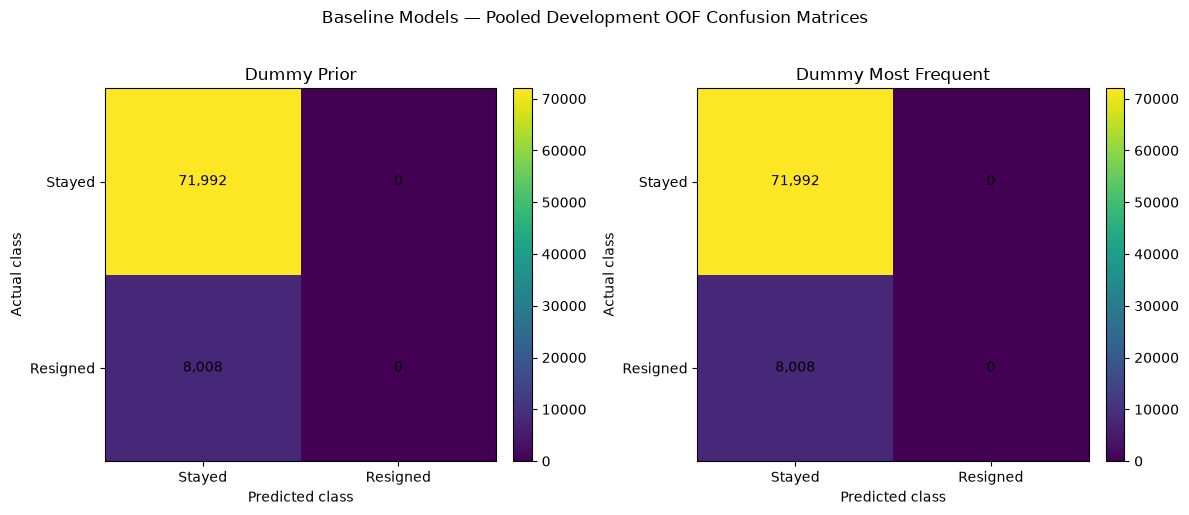

In [18]:
# ------------------------------------------------------------
# PLOT POOLED CONFUSION MATRICES
# ------------------------------------------------------------

model_count = len(
    oof_predictions_by_model
)

fig, axes = plt.subplots(
    1,
    model_count,
    figsize=(
        6 * model_count,
        5,
    ),
)


# Keep a consistent iterable shape when only one model exists.
if model_count == 1:
    axes = np.array([axes])
else:
    axes = np.asarray(axes).reshape(-1)


for ax, (
    model_name,
    predictions,
) in zip(
    axes,
    oof_predictions_by_model.items(),
):

    matrix = confusion_matrix(
        predictions["y_true"].astype(int),
        predictions["y_pred_0_5"].astype(int),
        labels=[0, 1],
    )


    image = ax.imshow(
        matrix,
        aspect="auto",
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

    ax.set_xticks(
        [0, 1],
        labels=[
            "Stayed",
            "Resigned",
        ],
    )

    ax.set_yticks(
        [0, 1],
        labels=[
            "Stayed",
            "Resigned",
        ],
    )


    # Add the four cell counts directly to each confusion matrix.
    for row_index in range(2):
        for column_index in range(2):
            ax.text(
                column_index,
                row_index,
                f"{matrix[row_index, column_index]:,}",
                ha="center",
                va="center",
            )


    fig.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04,
    )


fig.suptitle(
    "Baseline Models — Pooled Development OOF Confusion Matrices",
    y=1.02,
)

fig.tight_layout()


confusion_matrix_figure_file = (
    baseline_results_folder
    / "figure_01_baseline_confusion_matrices.png"
)

fig.savefig(
    confusion_matrix_figure_file,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

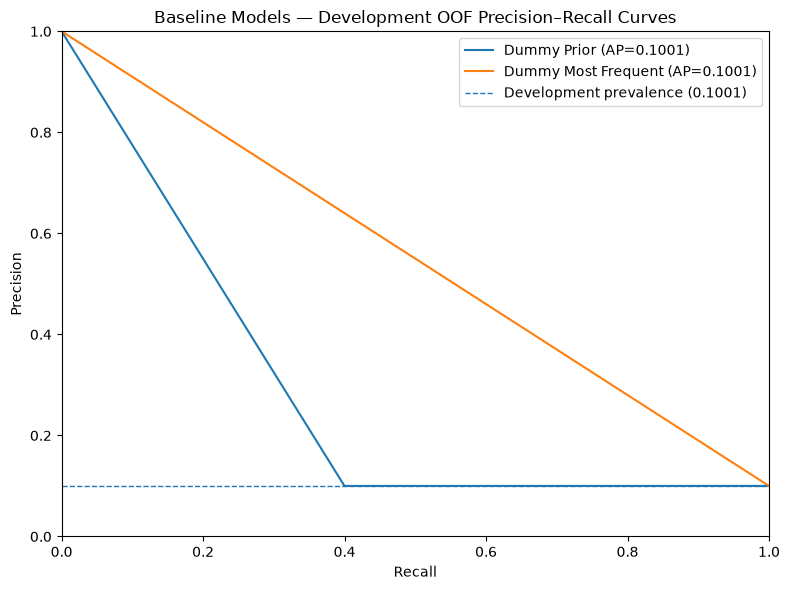

In [19]:
# ------------------------------------------------------------
# PLOT PRECISION–RECALL CURVES
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 6)
)


for model_name, predictions in oof_predictions_by_model.items():

    precision_values, recall_values, _ = precision_recall_curve(
        predictions["y_true"].astype(int),
        predictions["y_probability"].astype(float),
    )


    model_pr_auc = average_precision_score(
        predictions["y_true"].astype(int),
        predictions["y_probability"].astype(float),
    )


    ax.plot(
        recall_values,
        precision_values,
        label=(
            f"{model_name} "
            f"(AP={model_pr_auc:.4f})"
        ),
    )


# Positive prevalence provides a useful no-skill PR reference.
ax.axhline(
    development_positive_rate,
    linestyle="--",
    linewidth=1,
    label=(
        f"Development prevalence "
        f"({development_positive_rate:.4f})"
    ),
)

ax.set_title(
    "Baseline Models — Development OOF Precision–Recall Curves"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()

fig.tight_layout()


pr_curve_figure_file = (
    baseline_results_folder
    / "figure_02_baseline_precision_recall_curves.png"
)

fig.savefig(
    pr_curve_figure_file,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

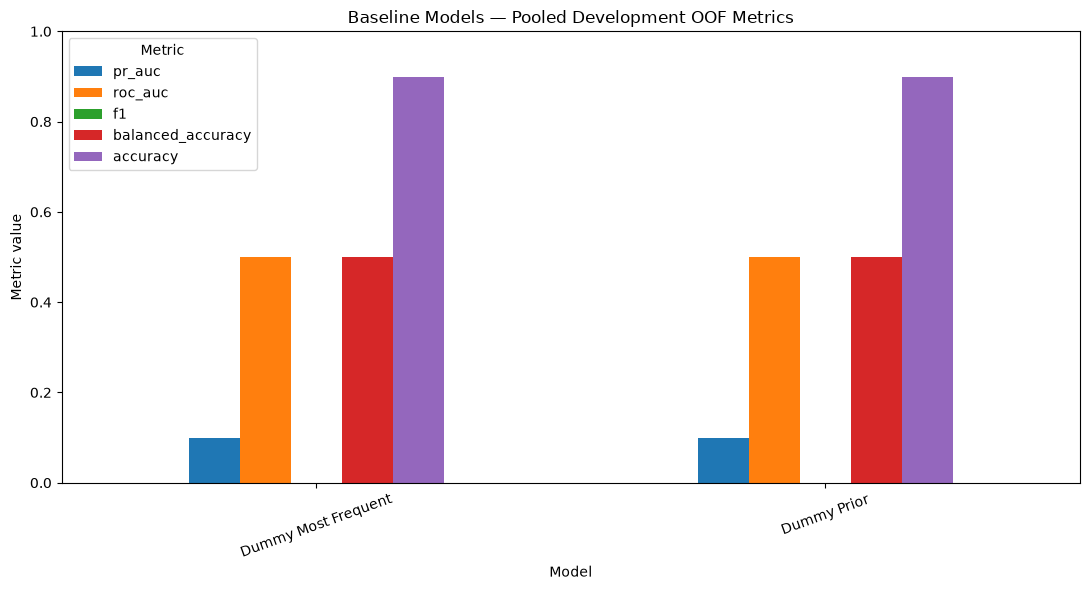

In [20]:
# ------------------------------------------------------------
# PLOT SELECTED BASELINE METRICS
# ------------------------------------------------------------

selected_metric_columns = [
    "pr_auc",
    "roc_auc",
    "f1",
    "balanced_accuracy",
    "accuracy",
]


plot_metrics = (
    baseline_summary_metrics[
        [
            "model_name",
            *selected_metric_columns,
        ]
    ]
    .set_index("model_name")
)


fig, ax = plt.subplots(
    figsize=(11, 6)
)

plot_metrics.plot(
    kind="bar",
    ax=ax,
)

ax.set_title(
    "Baseline Models — Pooled Development OOF Metrics"
)

ax.set_xlabel("Model")
ax.set_ylabel("Metric value")
ax.set_ylim(0, 1)

ax.tick_params(
    axis="x",
    rotation=20,
)

ax.legend(
    title="Metric",
)

fig.tight_layout()


metric_comparison_figure_file = (
    baseline_results_folder
    / "figure_03_baseline_metric_comparison.png"
)

fig.savefig(
    metric_comparison_figure_file,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

In [21]:
# ------------------------------------------------------------
# DOCUMENT BASELINE INTERPRETATION
# ------------------------------------------------------------

# Pull the actual pooled metrics into a compact interpretation table.
summary_by_model = (
    baseline_summary_metrics
    .set_index("model_name")
)


baseline_interpretation_rows = []


prior_metrics = summary_by_model.loc[
    dummy_prior_model_name
]

baseline_interpretation_rows.append(
    {
        "model_name": dummy_prior_model_name,
        "role": (
            "No-skill probability / ranking reference"
        ),
        "pr_auc": prior_metrics["pr_auc"],
        "accuracy": prior_metrics["accuracy"],
        "recall": prior_metrics["recall"],
        "interpretation": (
            "Uses only the training-fold class prior and provides "
            "no employee-level ranking signal."
        ),
    }
)


most_frequent_metrics = summary_by_model.loc[
    dummy_most_frequent_model_name
]

baseline_interpretation_rows.append(
    {
        "model_name": dummy_most_frequent_model_name,
        "role": (
            "Majority-class classification reference"
        ),
        "pr_auc": most_frequent_metrics["pr_auc"],
        "accuracy": most_frequent_metrics["accuracy"],
        "recall": most_frequent_metrics["recall"],
        "interpretation": (
            "Shows why high raw accuracy is misleading when the "
            "positive class is only about 10% of the development data."
        ),
    }
)


if RUN_OPTIONAL_LOGISTIC_REGRESSION:

    logistic_metrics = summary_by_model.loc[
        logistic_model_name
    ]

    baseline_interpretation_rows.append(
        {
            "model_name": logistic_model_name,
            "role": (
                "Optional conventional feature-based reference"
            ),
            "pr_auc": logistic_metrics["pr_auc"],
            "accuracy": logistic_metrics["accuracy"],
            "recall": logistic_metrics["recall"],
            "interpretation": (
                "Uses the frozen 17 predictors with fold-local "
                "one-hot encoding and numerical standardization."
            ),
        }
    )


baseline_interpretation = pd.DataFrame(
    baseline_interpretation_rows
)


display(baseline_interpretation)


baseline_interpretation_file = (
    baseline_results_folder
    / "baseline_interpretation.csv"
)

baseline_interpretation.to_csv(
    baseline_interpretation_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)

,model_name,role,pr_auc,accuracy,recall,interpretation
0,Dummy Prior,No-skill probability / ranking reference,0.100085,0.8999,0.0,Uses only the training-fold class prior and pr...
1,Dummy Most Frequent,Majority-class classification reference,0.100100,0.8999,0.0,Shows why high raw accuracy is misleading when...


## Baseline Interpretation

The mandatory Dummy models establish the minimum reference level for the
project.

The majority-class baseline is especially important because it demonstrates
that a high accuracy value can coexist with zero useful positive-class recall.

The prior baseline provides the no-skill probability/ranking reference used to
interpret later PR-AUC results.

The six advanced headline models should therefore be judged mainly by whether
they provide genuine cross-validated predictive lift above these references,
especially on PR-AUC and positive-class detection, rather than simply by
whether their raw accuracy exceeds the majority-class accuracy.

In [22]:
# ------------------------------------------------------------
# CREATE BASELINE OUTPUT MANIFEST
# ------------------------------------------------------------

expected_baseline_outputs = [
    dummy_prior_oof_file,
    dummy_most_frequent_oof_file,
    combined_oof_file,
    baseline_fold_metrics_file,
    baseline_summary_metrics_file,
    baseline_cv_metric_summary_file,
    baseline_interpretation_file,
    confusion_matrix_figure_file,
    pr_curve_figure_file,
    metric_comparison_figure_file,
    *confusion_matrix_files.values(),
]


# The optional Logistic Regression prediction file is required
# only if the optional benchmark was actually executed.
if RUN_OPTIONAL_LOGISTIC_REGRESSION:
    expected_baseline_outputs.append(
        logistic_oof_file
    )


output_manifest_rows = []


for output_file in expected_baseline_outputs:

    exists = output_file.exists()

    size_bytes = (
        output_file.stat().st_size
        if exists
        else 0
    )

    output_manifest_rows.append(
        {
            "file_name": output_file.name,
            "relative_path": str(
                output_file.relative_to(project_root)
            ),
            "exists": exists,
            "size_bytes": size_bytes,
        }
    )


baseline_output_manifest = pd.DataFrame(
    output_manifest_rows
)


display(baseline_output_manifest)


# Save the manifest itself.
baseline_output_manifest_file = (
    baseline_results_folder
    / "baseline_output_manifest.csv"
)

baseline_output_manifest.to_csv(
    baseline_output_manifest_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)


# results/baselines/ is no longer empty, so remove a redundant
# .gitkeep file if the repository contains one.
baseline_gitkeep = (
    baseline_results_folder
    / ".gitkeep"
)

if baseline_gitkeep.exists():
    baseline_gitkeep.unlink()

    print(
        "Removed results/baselines/.gitkeep because "
        "the folder now contains baseline outputs."
    )

,file_name,relative_path,exists,size_bytes
0,dummy_prior_oof_predictions.csv,results\baselines\dummy_prior_oof_predictions.csv,True,2823251
1,dummy_most_frequent_oof_predictions.csv,results\baselines\dummy_most_frequent_oof_pred...,True,2871251
2,baseline_oof_predictions_combined.csv,results\baselines\baseline_oof_predictions_com...,True,5694439
3,baseline_fold_metrics.csv,results\baselines\baseline_fold_metrics.csv,True,1155
4,baseline_summary_metrics.csv,results\baselines\baseline_summary_metrics.csv,True,914
5,baseline_cv_metric_summary.csv,results\baselines\baseline_cv_metric_summary.csv,True,593
6,baseline_interpretation.csv,results\baselines\baseline_interpretation.csv,True,412
7,figure_01_baseline_confusion_matrices.png,results\baselines\figure_01_baseline_confusion...,True,56225
8,figure_02_baseline_precision_recall_curves.png,results\baselines\figure_02_baseline_precision...,True,82364
9,figure_03_baseline_metric_comparison.png,results\baselines\figure_03_baseline_metric_co...,True,49179


Removed results/baselines/.gitkeep because the folder now contains baseline outputs.


In [23]:
# ------------------------------------------------------------
# FINAL BASELINE WORKFLOW VALIDATION
# ------------------------------------------------------------

# Revalidate frozen source files at the end of execution.
if sha256_file(raw_data_file) != expected_raw_sha256:
    raise ValueError(
        "Final validation failed: raw dataset changed during baseline work."
    )

if sha256_file(split_registry_file) != expected_registry_sha256:
    raise ValueError(
        "Final validation failed: split registry changed during baseline work."
    )


# The formal holdout must remain completely outside all OOF predictions.
for model_name, predictions in oof_predictions_by_model.items():

    validate_oof_predictions(
        predictions,
        model_name,
    )


# Every mandatory baseline must be present.
mandatory_model_names = {
    dummy_prior_model_name,
    dummy_most_frequent_model_name,
}

if not mandatory_model_names.issubset(
    set(oof_predictions_by_model)
):
    raise ValueError(
        "Final validation failed: a mandatory Dummy baseline is missing."
    )


# Verify exact target coverage in every OOF prediction set.
for model_name, predictions in oof_predictions_by_model.items():

    target_counts = (
        predictions["y_true"]
        .value_counts()
    )

    if int(target_counts[0]) != 71_992:
        raise ValueError(
            f"{model_name}: unexpected stayed target count."
        )

    if int(target_counts[1]) != 8_008:
        raise ValueError(
            f"{model_name}: unexpected resigned target count."
        )


# Verify every required saved output exists and is non-empty.
missing_or_empty_outputs = []

for output_file in (
    expected_baseline_outputs
    + [baseline_output_manifest_file]
):

    if (
        output_file is None
        or not output_file.exists()
        or output_file.stat().st_size == 0
    ):
        missing_or_empty_outputs.append(
            str(output_file)
        )


if missing_or_empty_outputs:
    raise ValueError(
        "Final validation failed. Missing or empty baseline outputs:\n"
        + "\n".join(missing_or_empty_outputs)
    )


# Verify the combined OOF table contains no formal holdout IDs.
combined_holdout_overlap = set(
    combined_oof_predictions["Employee_ID"]
).intersection(
    holdout_ids
)

if combined_holdout_overlap:
    raise ValueError(
        "Final validation failed: formal holdout ID found "
        "in combined baseline OOF predictions."
    )


# Confirm that no alternative split/fold mechanism was required.
# The notebook has used only the existing cv_fold column from
# the frozen split registry.
print("FINAL BASELINE WORKFLOW VALIDATION")
print("-" * 60)

print("Raw dataset checksum:                      PASSED")
print("Frozen split registry checksum:            PASSED")
print("Frozen feature contract status:            PASSED")
print("Development rows used:                     80,000")
print("Formal holdout rows evaluated:             0")
print("Frozen CV folds used:                      5")
print("Validation rows per fold:                  16,000")
print("Dummy Prior OOF rows:                      80,000")
print("Dummy Most Frequent OOF rows:              80,000")
print(
    "Optional Logistic Regression executed:     "
    f"{RUN_OPTIONAL_LOGISTIC_REGRESSION}"
)
print("Mandatory baseline output files:           PASSED")
print("Private train/test split created:           NO")
print("Private CV folds created:                   NO")
print("SMOTE / resampling used:                    NO")
print("Formal holdout used for decisions:          NO")
print("Headline models trained:                    NO")
print("Universal preprocessed dataset created:     NO")

print("\nBaseline modelling validation: PASSED")

Dummy Prior: OOF validation PASSED (80,000 rows)
Dummy Most Frequent: OOF validation PASSED (80,000 rows)
FINAL BASELINE WORKFLOW VALIDATION
------------------------------------------------------------
Raw dataset checksum:                      PASSED
Frozen split registry checksum:            PASSED
Frozen feature contract status:            PASSED
Development rows used:                     80,000
Formal holdout rows evaluated:             0
Frozen CV folds used:                      5
Validation rows per fold:                  16,000
Dummy Prior OOF rows:                      80,000
Dummy Most Frequent OOF rows:              80,000
Optional Logistic Regression executed:     False
Mandatory baseline output files:           PASSED
Private train/test split created:           NO
Private CV folds created:                   NO
SMOTE / resampling used:                    NO
Formal holdout used for decisions:          NO
Headline models trained:                    NO
Universal preprocessed d

## Baseline Modelling Conclusion

The shared baseline workflow is complete.

The mandatory no-skill references were evaluated using the frozen 80,000-row
development partition and the exact five saved cross-validation folds.

Every mandatory baseline generated exactly one out-of-fold probability for
each development employee, with zero formal-holdout records included.

The notebook reports and saves:

- PR-AUC / Average Precision;
- ROC-AUC;
- precision;
- recall;
- F1;
- balanced accuracy;
- accuracy;
- Brier score;
- pooled confusion matrices;
- per-fold metrics;
- CV mean and standard deviation;
- complete OOF prediction files.

`DummyClassifier(strategy="prior")` provides the no-skill probability/ranking
reference.

`DummyClassifier(strategy="most_frequent")` provides the majority-class
classification reference and demonstrates why raw accuracy is insufficient for
this imbalanced target.

The optional Logistic Regression reference is not required for baseline
completion and remains disabled unless the group explicitly chooses to run it.

No formal holdout evaluation, headline-model training, model selection,
calibration selection, threshold optimization, fairness conclusion, resampling,
or retention prioritization was performed.

The baseline artefacts under `results/baselines/` now provide common reference
evidence for the six advanced model workstreams and the later
`11_model_comparison.ipynb`.